# 03 · An honest backtest

A **backtest** simulates what would have happened trading a rule in the past. It is easy to fool yourself, so there are three rules:

1. **Split in time.** Pick the rule looking only at the **first 2/3** of the data and test it on the **last 1/3**, never seen. Like studying with some exercises and sitting the exam with others.
2. **Pay fees** on every trade, and **funding** while the position is open.
3. **Try variations.** If it only works in one exact case, it was probably luck.

**The rule:** if the funding z-score goes above a threshold, bet on a **drop** for H hours (*short*). If it goes below minus the threshold, bet on a **rise** (*long*).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

COINS = ["HYPE", "BTC", "ETH", "SOL"]
COIN = "HYPE"   # Hyperliquid's own token; change to "BTC", "ETH" or "SOL" to look at another coin
df = pd.read_csv(f"../data/{COIN}.csv", parse_dates=["time"])
H = 8
FEE = 0.00035  # 0.035% per trade (check Hyperliquid's current fee)
W = 168
df["z"] = (df["fundingRate"] - df["fundingRate"].rolling(W).mean()) / df["fundingRate"].rolling(W).std()
df = df.dropna(subset=["z"]).reset_index(drop=True)

## The simulation

It walks the hours in order. With no open position, if z crosses the threshold, it opens one and holds it for H hours. Each trade's result is:

`result = direction × price return − 2 fees (in and out) − direction × funding paid`

(direction = +1 for long, −1 for short; a long pays positive funding and a short collects it).

In [2]:
def backtest(d, threshold, H=H):
    trades, i = [], 0
    while i < len(d) - H:
        z = d.at[i, "z"]
        if abs(z) >= threshold:
            side = -1 if z > 0 else 1
            ret = d.at[i + H, "close"] / d.at[i, "close"] - 1
            fund = d["fundingRate"].iloc[i + 1:i + H + 1].fillna(0).sum()
            trades.append({"time": d.at[i, "time"], "side": side, "pnl": side * ret - 2 * FEE - side * fund})
            i += H  # no new trade until this one closes
        else:
            i += 1
    return pd.DataFrame(trades)


def measure(trades, name=""):
    if trades.empty:
        return {"name": name, "trades": 0}
    curve = trades["pnl"].cumsum()
    per_year = len(trades) / ((trades.time.max() - trades.time.min()).days / 365 + 1e-9)
    return {
        "name": name,
        "trades": len(trades),
        "total %": round(trades.pnl.sum() * 100, 2),
        "win rate %": round((trades.pnl > 0).mean() * 100, 1),
        "sharpe": round(trades.pnl.mean() / trades.pnl.std() * np.sqrt(per_year), 2) if trades.pnl.std() > 0 else None,
        "max drawdown %": round((curve - curve.cummax()).min() * 100, 2),
    }

## Step 1: pick the threshold **using the training period only**

Try three thresholds on the first 2/3 and keep the best. The test period stays untouched.

In [3]:
cut = int(len(df) * 2 / 3)
train, test = df.iloc[:cut].reset_index(drop=True), df.iloc[cut:].reset_index(drop=True)
print("Train:", train.time.min().date(), "→", train.time.max().date())
print("Test: ", test.time.min().date(), "→", test.time.max().date())

res = pd.DataFrame([measure(backtest(train, t), f"threshold {t}") for t in [1.5, 2.0, 2.5]])
res

Train: 2026-04-14 → 2026-08-20
Test:  2026-08-20 → 2026-10-24


,name,trades,total %,win rate %,sharpe,max drawdown %
0,threshold 1.5,116,21.74,48.3,1.23,-20.94
1,threshold 2.0,94,35.58,53.2,2.04,-15.51
2,threshold 2.5,73,40.19,57.5,3.13,-9.49


## Step 2: the real test

Use the chosen threshold on the **test** period, never looked at. **This is the result that counts.**

- Wins in training but loses in test: it was chance (*overfitting*).
- Wins in both: possible signal, keep testing.

{'name': 'TEST · threshold 2.5', 'trades': 33, 'total %': np.float64(2.32), 'win rate %': np.float64(48.5), 'sharpe': np.float64(0.51), 'max drawdown %': np.float64(-10.53)}


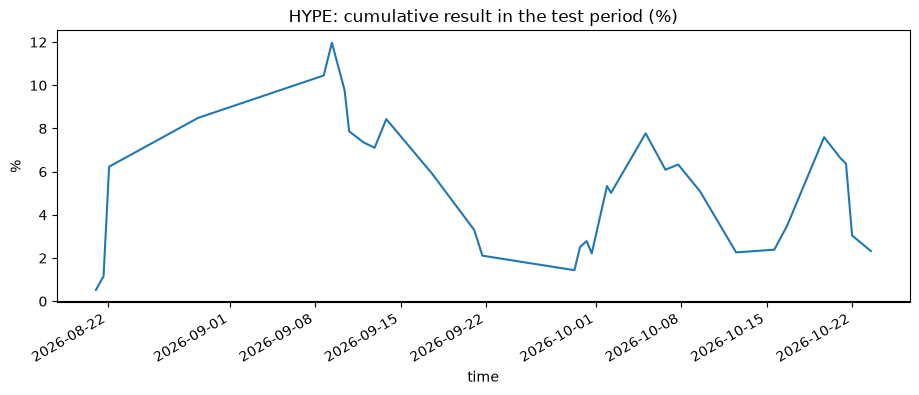

In [4]:
best = float(res.sort_values("total %", ascending=False).iloc[0]["name"].split()[-1])
trades = backtest(test, best)
print(measure(trades, f"TEST · threshold {best}"))

if not trades.empty:
    (trades.set_index("time")["pnl"].cumsum() * 100).plot(title=f"{COIN}: cumulative result in the test period (%)")
    plt.axhline(0, color="black", lw=0.8); plt.ylabel("%"); plt.show()

## Step 3: robustness

Does it also work on other coins and other horizons? If the gain shows up in only one exact combination, it is most likely luck.

In [5]:
rows = []
for coin in COINS:
    d = pd.read_csv(f"../data/{coin}.csv", parse_dates=["time"])
    d["z"] = (d["fundingRate"] - d["fundingRate"].rolling(W).mean()) / d["fundingRate"].rolling(W).std()
    d = d.dropna(subset=["z"]).reset_index(drop=True)
    t = d.iloc[int(len(d) * 2 / 3):].reset_index(drop=True)
    for h in [4, 8, 24]:
        rows.append(measure(backtest(t, best, H=h), f"{coin} · {h} h"))
pd.DataFrame(rows)

,name,trades,total %,win rate %,sharpe,max drawdown %
0,HYPE · 4 h,41,-0.06,58.5,-0.01,-8.84
1,HYPE · 8 h,33,2.32,48.5,0.51,-10.53
2,HYPE · 24 h,22,-23.30,40.9,-2.86,-32.11
3,BTC · 4 h,35,-3.65,34.3,-2.73,-4.63
4,BTC · 8 h,28,0.49,57.1,0.28,-2.87
5,BTC · 24 h,17,-7.69,47.1,-3.20,-7.61
6,ETH · 4 h,23,1.50,47.8,0.63,-8.19
7,ETH · 8 h,18,2.45,44.4,1.04,-6.09
8,ETH · 24 h,12,4.01,50.0,1.93,-5.27
9,SOL · 4 h,34,1.00,58.8,0.29,-3.78


## Glossary
- **trades:** how many trades it made.
- **total %:** the sum of all trades, after fees and funding.
- **win rate %:** the share of winning trades.
- **sharpe:** return per unit of risk, annualized. Above 1 is good; above 2 is suspiciously good (check for a bug).
- **max drawdown %:** the most it lost from a peak. It measures how much pain you'd sit through.

## What goes in the README
- The **test period** result (not the training one).
- The robustness table.
- The limitations: a few months of data, one market regime, approximate fees, no slippage.